# Supplier SLA & Delivery Delay Risk: End-to-End Notebook

**Business question:** *Can we predict, at the moment a Purchase Order (PO) line is scheduled, whether it will be delivered late?*

**Data:** USAID SCMS Global Delivery History (10,324 PO lines, 33 columns).
**Target:** `is_late = 1` if `Delivered to Client Date` is later than `Scheduled Delivery Date`.
**Primary metric:** ROC-AUC (secondary: PR-AUC and F1 at a tuned threshold), because only about 11.5% of lines are late.

**Notebook roadmap**
1. First look at the data and missing values (the "missing value funnel")
2. Date parsing and target definition
3. EDA: what drives late deliveries?
4. ERP anomaly parsing and point-in-time feature engineering
5. Train/validation/test split and leakage-free preprocessing
6. Model training and hyperparameter tuning (Logistic Regression, Random Forest, XGBoost)
7. Threshold optimisation, final test evaluation, feature importance
8. Saving the model for the FastAPI service (`train.py` reproduces this pipeline)

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import sklearn
import datetime
import missingno as msno
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("data/SCMS_Delivery_History_Dataset.csv")
df.head(5)

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


The dataset has **10,324 rows x 33 columns**: supplier/sourcing attributes, logistics attributes, commercial values and milestone dates. We now check the types and the first rows.

Let us look at our dataset and its variables

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  str    
 2   PQ #                          10324 non-null  str    
 3   PO / SO #                     10324 non-null  str    
 4   ASN/DN #                      10324 non-null  str    
 5   Country                       10324 non-null  str    
 6   Managed By                    10324 non-null  str    
 7   Fulfill Via                   10324 non-null  str    
 8   Vendor INCO Term              10324 non-null  str    
 9   Shipment Mode                 9964 non-null   str    
 10  PQ First Sent to Client Date  10324 non-null  str    
 11  PO Sent to Vendor Date        10324 non-null  str    
 12  Scheduled Delivery Date       10324 non-null  str    
 13  Delivered to

In [4]:
df[df.columns[0:16]].head(30)

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,PQ First Sent to Client Date,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date,Product Group
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,2-Jun-06,2-Jun-06,2-Jun-06,HRDT
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,14-Nov-06,14-Nov-06,14-Nov-06,ARV
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,Pre-PQ Process,Date Not Captured,27-Aug-06,27-Aug-06,27-Aug-06,HRDT
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,1-Sep-06,1-Sep-06,1-Sep-06,ARV
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,11-Aug-06,11-Aug-06,11-Aug-06,ARV
5,23,112-NG-T01,Pre-PQ Process,SCMS-87,ASN-57,Nigeria,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,28-Sep-06,28-Sep-06,28-Sep-06,ARV
6,44,110-ZM-T01,Pre-PQ Process,SCMS-139,ASN-130,Zambia,PMO - US,Direct Drop,DDU,Air,Pre-PQ Process,Date Not Captured,8-Jan-07,8-Jan-07,8-Jan-07,ARV
7,45,109-TZ-T01,Pre-PQ Process,SCMS-140,ASN-94,Tanzania,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,24-Nov-06,24-Nov-06,24-Nov-06,ARV
8,46,112-NG-T01,Pre-PQ Process,SCMS-156,ASN-93,Nigeria,PMO - US,Direct Drop,EXW,Air,Pre-PQ Process,Date Not Captured,7-Dec-06,7-Dec-06,7-Dec-06,ARV
9,47,110-ZM-T01,Pre-PQ Process,SCMS-165,ASN-199,Zambia,PMO - US,Direct Drop,CIP,Air,Pre-PQ Process,11/13/06,30-Jan-07,30-Jan-07,30-Jan-07,ARV


In [5]:
df[df.columns[16:33]].head(30)

,Sub Classification,Vendor,Item Description,Molecule/Test Type,Brand,Dosage,Dosage Form,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,HIV test,RANBAXY Fine Chemicals LTD.,"HIV, Reveal G3 Rapid HIV-1 Antibody Test, 30 T...","HIV, Reveal G3 Rapid HIV-1 Antibody Test",Reveal,NaN,Test kit,30,19,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,Pediatric,Aurobindo Pharma Limited,"Nevirapine 10mg/ml, oral suspension, Bottle, 2...",Nevirapine,Generic,10mg/ml,Oral suspension,240,1000,6200.00,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,HIV test,Abbott GmbH & Co. KG,"HIV 1/2, Determine Complete HIV Kit, 100 Tests","HIV 1/2, Determine Complete HIV Kit",Determine,NaN,Test kit,100,500,40000.00,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,Adult,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...,"Lamivudine 150mg, tablets, 60 Tabs",Lamivudine,Generic,150mg,Tablet,60,31920,127360.80,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,38000,121600.00,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN
5,Pediatric,Aurobindo Pharma Limited,"Zidovudine 10mg/ml, oral solution, Bottle, 240 ml",Zidovudine,Generic,10mg/ml,Oral solution,240,416,2225.60,5.35,0.02,"Aurobindo Unit III, India",Yes,504,5920.42,NaN
6,Pediatric,MERCK SHARP & DOHME IDEA GMBH (FORMALLY MERCK ...,"Efavirenz 200mg [Stocrin/Sustiva], capsule, 90...",Efavirenz,Stocrin/Sustiva,200mg,Capsule,90,135,4374.00,32.40,0.36,MSD South Granville Australia,Yes,328,Freight Included in Commodity Cost,NaN
7,Adult,Aurobindo Pharma Limited,"Nevirapine 200mg, tablets, 60 Tabs",Nevirapine,Generic,200mg,Tablet,60,16667,60834.55,3.65,0.06,"Aurobindo Unit III, India",Yes,1478,6212.41,NaN
8,Adult,Aurobindo Pharma Limited,"Stavudine 30mg, capsules, 60 Caps",Stavudine,Generic,30mg,Capsule,60,273,532.35,1.95,0.03,"Aurobindo Unit III, India",No,See ASN-93 (ID#:1281),See ASN-93 (ID#:1281),NaN
9,Adult,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),"Lopinavir/Ritonavir 200/50mg [Aluvia], tablets...",Lopinavir/Ritonavir,Aluvia,200/50mg,Tablet,120,2800,115080.00,41.10,0.34,ABBVIE (Abbott) St. P'burg USA,Yes,643,Freight Included in Commodity Cost,NaN


We noticed that a few columns contain mising variables and tha that potential some date variables are showing as string. We will need to handle those

In [6]:
df.describe()

,ID,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Line Item Insurance (USD)
count,10324.000000,10324.000000,10324.000000,1.032400e+04,10324.000000,10324.000000,10037.000000
mean,51098.968229,77.990895,18332.534870,1.576506e+05,21.910241,0.611701,240.117626
std,31944.332496,76.579764,40035.302961,3.452921e+05,45.609223,3.275808,500.190568
min,1.000000,1.000000,1.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,12795.750000,30.000000,408.000000,4.314593e+03,4.120000,0.080000,6.510000
50%,57540.500000,60.000000,3000.000000,3.047147e+04,9.300000,0.160000,47.040000
75%,83648.250000,90.000000,17039.750000,1.664471e+05,23.592500,0.470000,252.400000
max,86823.000000,1000.000000,619999.000000,5.951990e+06,1345.640000,238.650000,7708.440000


<Axes: xlabel='Product Group', ylabel='count'>

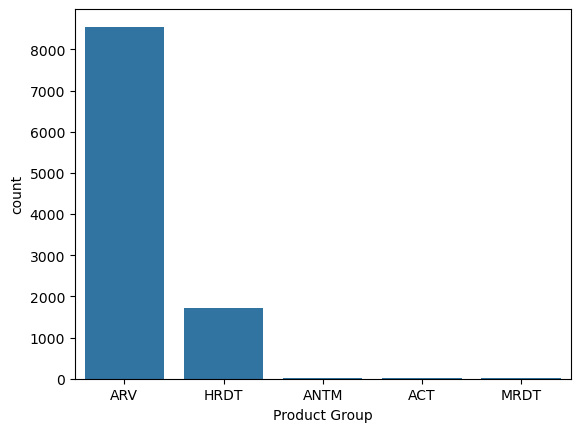

In [7]:
sns.barplot(df['Product Group'].value_counts())

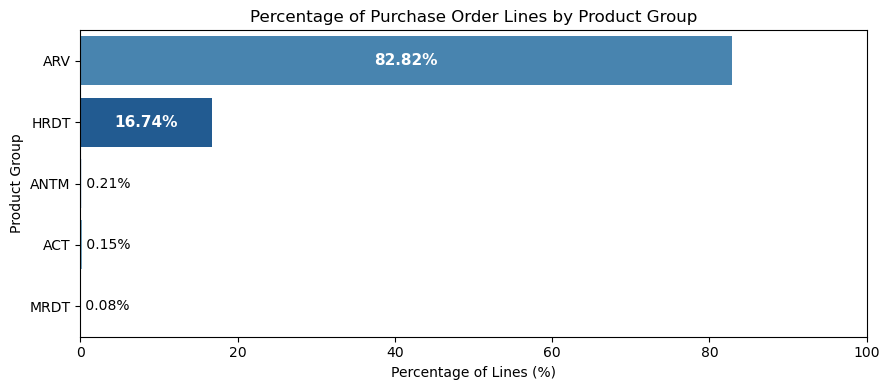

In [8]:
plt.figure(figsize=(9, 4))
ax = sns.countplot(
        data=df,
        y='Product Group',
        hue='Product Group',
        order=df['Product Group'].value_counts().index,
        stat='percent',
        palette='Blues_r',
        legend=False
    )
    
    # Loop over all containers and adapt label position & color
for c in ax.containers:
    for bar in c:
        width = bar.get_width()
        y_pos = bar.get_y() + bar.get_height() / 2

        if width > 10:
                # Inside the bar in bold white text
            ax.annotate(
                    f'{width:.2f}%',
                    (width / 2, y_pos),
                    ha='center', va='center',
                    color='white', fontweight='bold', fontsize=11
                )
        else:
                # Just outside the tiny bars in black text
            ax.annotate(
                    f' {width:.2f}%',
                    (width, y_pos),
                    ha='left', va='center',
                    color='black', fontsize=10
                )

plt.title('Percentage of Purchase Order Lines by Product Group')
plt.xlabel('Percentage of Lines (%)')
plt.ylabel('Product Group')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

Look more closely at all the PO lines we can say the following about the Product Code split in our dataset:

• ARV (Antiretroviral drugs): ~82.82% of all PO lines

• HRDT (HIV Rapid Diagnostic Tests): ~16.74%

• ANTM, ACT, MRDT (Antimalarials / others): Long-tail specialized items making up the remaining < 0.5%

In [9]:
df.head()

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


**Analyzing missing values and cleaning out dataset**

In [10]:
#Let us check the missing variables
df.isnull().sum() 

ID                                 0
Project Code                       0
PQ #                               0
PO / SO #                          0
ASN/DN #                           0
Country                            0
Managed By                         0
Fulfill Via                        0
Vendor INCO Term                   0
Shipment Mode                    360
PQ First Sent to Client Date       0
PO Sent to Vendor Date             0
Scheduled Delivery Date            0
Delivered to Client Date           0
Delivery Recorded Date             0
Product Group                      0
Sub Classification                 0
Vendor                             0
Item Description                   0
Molecule/Test Type                 0
Brand                              0
Dosage                          1736
Dosage Form                        0
Unit of Measure (Per Pack)         0
Line Item Quantity                 0
Line Item Value                    0
Pack Price                         0
U

In [11]:
null_values = df.isnull().sum()

In [12]:
print("These are the variables with missing values in our df:")
df.isnull().sum()[lambda x: x > 0]

These are the variables with missing values in our df:


Shipment Mode                 360
Dosage                       1736
Line Item Insurance (USD)     287
dtype: int64

In [13]:
missing_summary = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': (df.isnull().mean() * 100).round(2)
})
missing_summary = missing_summary[missing_summary['missing_count'] > 0].sort_values(by='missing_pct', ascending=False)
missing_summary

,missing_count,missing_pct
Dosage,1736,16.82
Shipment Mode,360,3.49
Line Item Insurance (USD),287,2.78


**Takeaway:** only three columns have missing values: `Dosage` (about 17%), `Shipment Mode` (about 3.5%) and `Line Item Insurance (USD)` (a few percent). Missingness is therefore limited, but the rest of this section checks *why* values are missing before deciding how to fill them, because the reason determines the correct treatment.

In [14]:
df_missing = df[df['Dosage'].isnull()]
df_present = df[df['Dosage'].notnull()]

print(f"Rows missing Dosage: {len(df_missing)}")
print(f"Rows with Dosage:    {len(df_present)}")

Rows missing Dosage: 1736
Rows with Dosage:    8588


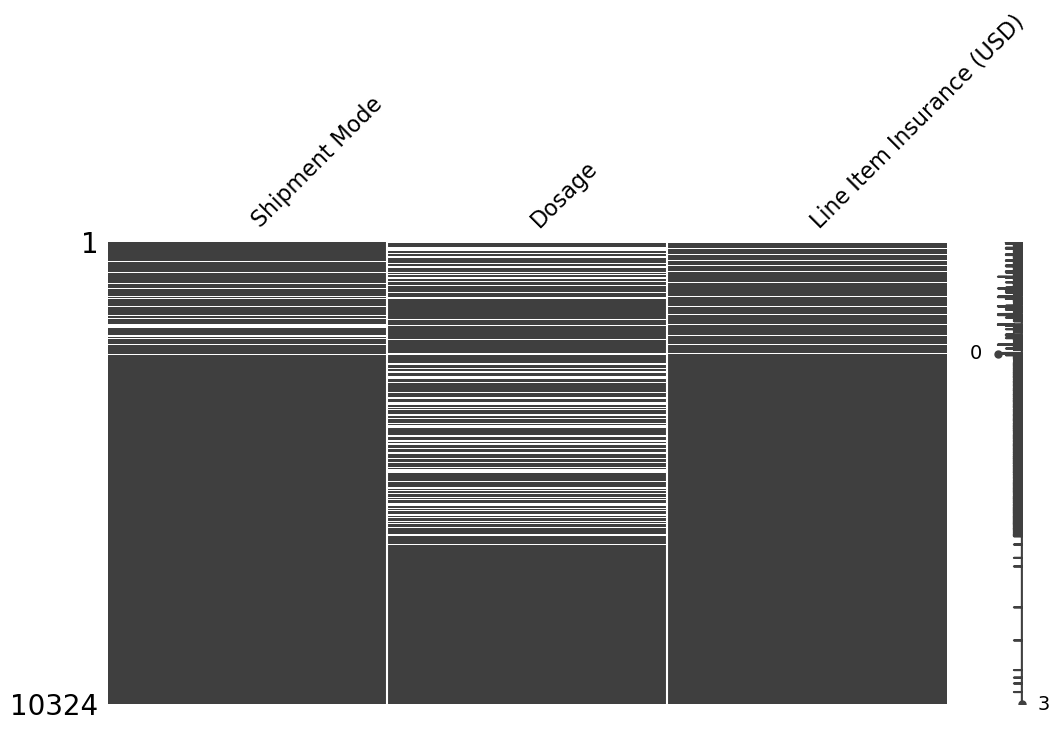

In [15]:
# Filter down to only columns that have at least one missing value
null_cols = df.columns[df.isnull().any()]

# Plot matrix
msno.matrix(df[null_cols], figsize=(12, 6))
plt.show()

The matrix confirms that missing values are not scattered randomly: they form solid blocks, which suggests structural causes (business rules) rather than random data-entry gaps.

There seems to be some sort of correlation between missing values in "Shipment mode" and "line item insurance". But do they have some sort of correlation with other variables? Let us just check

**The Dendrogram (msno.dendrogram)**

Groups columns in a tree by their missingness pattern:

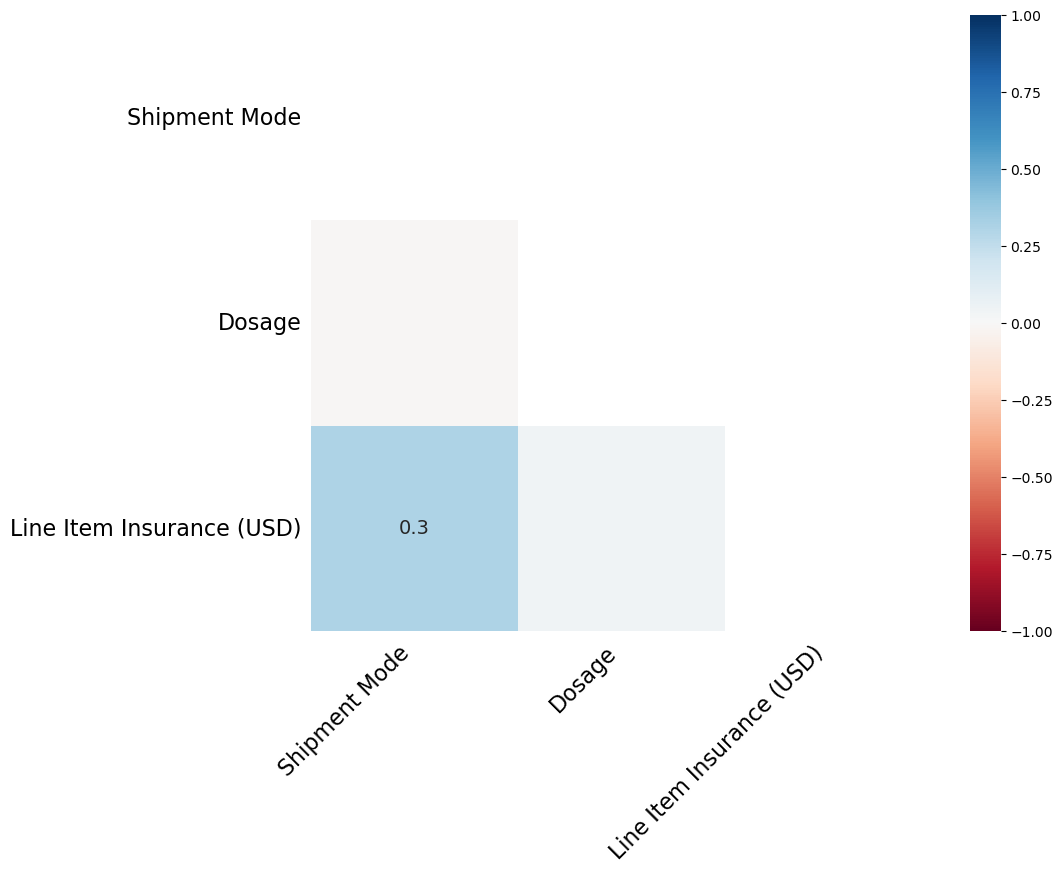

In [16]:
msno.heatmap(df[null_cols], figsize=(10, 8))
plt.show()

The heatmap measures how strongly missingness in one column predicts missingness in another. The three columns are only weakly linked to each other, so each one has its own cause. We investigate them one by one in Patterns A, B and C below.

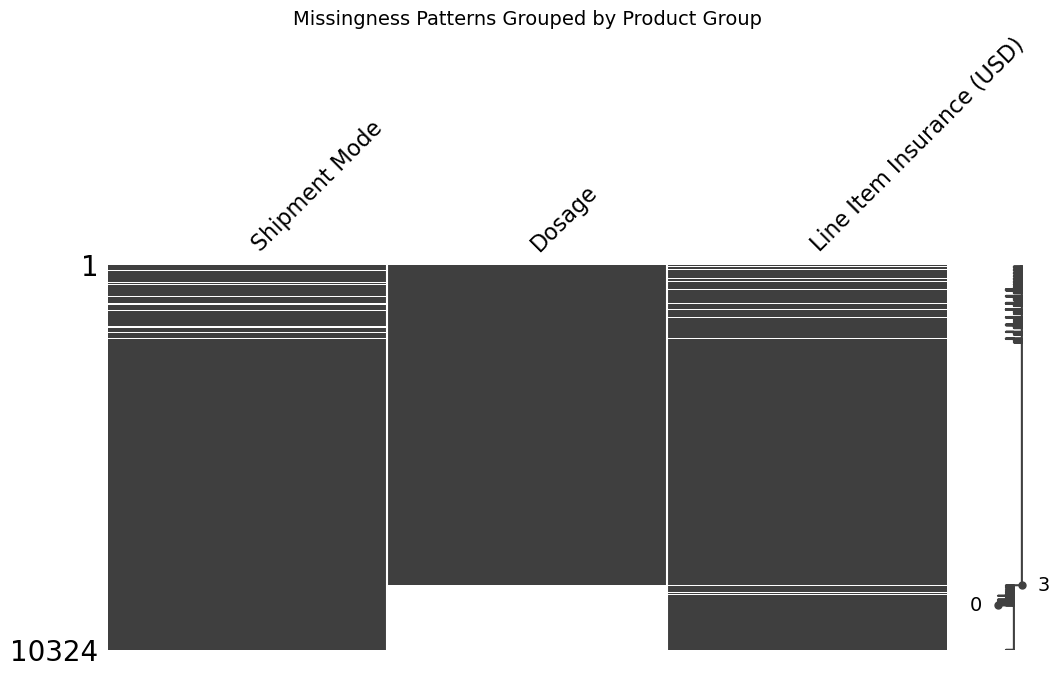

In [17]:
# Sort by Product Group to see if missingness clusters by product type
if 'Product Group' in df.columns:
    sorted_by_prod = df.sort_values(by='Product Group')
    msno.matrix(sorted_by_prod[null_cols], figsize=(12, 5))
    plt.title("Missingness Patterns Grouped by Product Group", fontsize=14)
    plt.show()

After sorting by `Product Group`, the `Dosage` gap lines up with specific product groups. This visual hint is quantified in Pattern A.

**Pattern A: Dosage vs Product Group**

Medical products like HIV test kits, diagnostics, or condoms are medical devices—they do not have a dosage. Only pharmaceuticals (like ARVs) do:

In [18]:
if 'Product Group' in df.columns and 'Dosage' in df.columns:
    # Cross-tab showing % missing dosage by Product Group
    dosage_pattern = pd.crosstab(
        df['Product Group'],
        df['Dosage'].isnull(),
        rownames=['Product Group'],
        colnames=['Is Dosage Missing?'],
        normalize='index'
    ) * 100
    display(dosage_pattern.round(1))

Is Dosage Missing?,False,True
Product Group,,
ACT,100.0,0.0
ANTM,100.0,0.0
ARV,100.0,0.0
HRDT,0.0,100.0
MRDT,0.0,100.0


From the above we can clearly see that missing values in the dosage filled are clearly linked to specific Product Group

**Pattern B: Shipment Mode vs Country / Fulfill Via**

Shipment mode is often missing for local fulfillment or domestic handoffs:

In [19]:
# Check % missing Shipment Mode per Country (Top 10 highest missing)
if 'Country' in df.columns and 'Shipment Mode' in df.columns:
    missing_ship_country = df.groupby('Country')['Shipment Mode'].apply(
        lambda s: s.isnull().mean() * 100
    ).sort_values(ascending=False).head(10)
    
    print("Top 10 Countries by % Missing Shipment Mode:")
    print(missing_ship_country.round(1))

Top 10 Countries by % Missing Shipment Mode:
Country
Zambia           14.5
Côte d'Ivoire    10.4
Ethiopia          8.3
Botswana          4.3
Tanzania          3.9
Nigeria           3.0
South Africa      3.0
Zimbabwe          2.2
Guyana            2.1
Namibia           2.1
Name: Shipment Mode, dtype: float64


**Pattern B result:** missing `Shipment Mode` is concentrated in a few countries (Zambia 14.5%, Côte d'Ivoire 10.4%, Ethiopia 8.3%) and is low elsewhere. It looks like a country or local-handoff recording practice, not a random gap. We will keep it as its own category (`Not Applicable`) so the model can learn from it. Late rate for this group is very low (about 1%, see the shipment-mode EDA below), so the flag is informative.

**Pattern C: Line Item Insurance (USD) vs Total Costs / Year**

Line item insurance is often missing when costs were rolled up at the order level or before standardized line-item accounting:

In [20]:
if 'Line Item Insurance (USD)' in df.columns:
    # Check relationship with Scheduled Delivery Year
    df['year'] = pd.to_datetime(df['Scheduled Delivery Date'], errors='coerce').dt.year
    missing_ins_year = df.groupby('year')['Line Item Insurance (USD)'].apply(
        lambda s: s.isnull().mean() * 100
    )
    print("Percentage Missing Insurance by Year:")
    print(missing_ins_year.round(1))

Percentage Missing Insurance by Year:
year
2006    100.0
2007     33.0
2008      0.0
2009      0.0
2010      0.0
2011      0.0
2012      0.0
2013      0.0
2014      0.0
2015      0.0
Name: Line Item Insurance (USD), dtype: float64


/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipykernel_84155/1286190167.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['year'] = pd.to_datetime(df['Scheduled Delivery Date'], errors='coerce').dt.year


Most PO lines with a missing "'Line Item Insurance (USD)" values dateed from 2006, 2007. Why?

**Answer to the question above (Pattern C):** missing insurance values are a *legacy-data effect*. 100% of 2006 lines and 33% of 2007 lines are missing, and from 2008 onwards nothing is missing. Insurance was apparently only recorded at line level after standard line-item accounting was introduced.

#### Decision matrix: how we handle each missing-value pattern

| Column | Root cause | Type | Action |
| :--- | :--- | :--- | :--- |
| `Dosage` | Structurally absent for HRDT/MRDT (test kits have no dosage; 100% missing in these groups, 0% in ARV/ACT/ANTM) | Structural | Fill with `Not Applicable` |
| `Shipment Mode` | Concentrated in a few countries / local handoffs | Process-related | Fill with `Not Applicable` (kept as a category) |
| `Line Item Insurance (USD)` | Not recorded before 2008 | Temporal / legacy | Fill with `0` (no insurance recorded) |

These fills are constants (not statistics learned from the data), so applying them before the train/validation/test split does not leak information. Numeric medians, which *are* learned from data, are computed after the split (section 3).

In [21]:
df['Dosage'] = df['Dosage'].fillna('Not Applicable')
df['Shipment Mode'] = df['Shipment Mode'].fillna( 'Not Applicable')
df['Line Item Insurance (USD)'] = df['Line Item Insurance (USD)'].fillna(0)


In [22]:
df["Dosage"].value_counts()

Dosage
Not Applicable     1736
300mg               990
200mg               932
600mg               772
150/300mg           600
150/300/200mg       580
10mg/ml             552
150mg               431
200/50mg            395
300/300mg           301
600/300/300mg       286
150/200/30mg        250
100mg               228
50mg                174
200/300mg           160
80/20mg/ml          158
400mg               156
20mg/ml             152
30mg                144
600/200/300mg       139
150/30mg            133
30/50/60mg          127
300/200mg            94
30/60mg              89
250mg                88
100/25mg             73
60/30mg              73
600/300mg            63
1mg/ml               54
300/100mg            54
20mg                 43
25mg                 39
15mg                 38
30mg/ml              33
300/150/300mg        28
30/50/6mg            19
30/6mg               14
80mg/ml              13
500/25mg             13
20/120mg             12
60/100/12mg          12
2g       

Now let us format the date variables as they are currently showing as simple strings.

In [25]:
date_var = ['PO Sent to Vendor Date', 'Scheduled Delivery Date', 'Delivered to Client Date', 'Delivery Recorded Date']
for i in date_var:
    df[i] = pd.to_datetime(df[i], errors='coerce')


/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipykernel_84155/3073182548.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[i] = pd.to_datetime(df[i], errors='coerce')
/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipykernel_84155/3073182548.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[i] = pd.to_datetime(df[i], errors='coerce')
/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipykernel_84155/3073182548.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[i] = pd.to_datetime(df[i], errors='coerce')
/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipyker

The date columns were read as text. `pd.to_datetime(..., errors='coerce')` converts them to real datetimes and turns anything unparseable (for example `"N/A - From RDC"` in `PO Sent to Vendor Date`) into `NaT` (missing). The *"Could not infer format"* warning is harmless: pandas parses each value individually because the file mixes several date formats.

In [26]:
#Other alternative posible
#df[date_var].apply(pd.to_datetime(errors='coerce'))

In [27]:
df[['PO Sent to Vendor Date','Scheduled Delivery Date', 'Delivered to Client Date','Delivery Recorded Date']].head(10)

,PO Sent to Vendor Date,Scheduled Delivery Date,Delivered to Client Date,Delivery Recorded Date
0,NaT,2006-06-02,2006-06-02,2006-06-02
1,NaT,2006-11-14,2006-11-14,2006-11-14
2,NaT,2006-08-27,2006-08-27,2006-08-27
3,NaT,2006-09-01,2006-09-01,2006-09-01
4,NaT,2006-08-11,2006-08-11,2006-08-11
5,NaT,2006-09-28,2006-09-28,2006-09-28
6,NaT,2007-01-08,2007-01-08,2007-01-08
7,NaT,2006-11-24,2006-11-24,2006-11-24
8,NaT,2006-12-07,2006-12-07,2006-12-07
9,2006-11-13,2007-01-30,2007-01-30,2007-01-30


In [28]:
df[date_var].dtypes

PO Sent to Vendor Date      datetime64[us]
Scheduled Delivery Date     datetime64[us]
Delivered to Client Date    datetime64[us]
Delivery Recorded Date      datetime64[us]
dtype: object

All four date columns are now `datetime64`, so we can do date arithmetic on them.

In [29]:
df.columns

Index(['ID', 'Project Code', 'PQ #', 'PO / SO #', 'ASN/DN #', 'Country',
       'Managed By', 'Fulfill Via', 'Vendor INCO Term', 'Shipment Mode',
       'PQ First Sent to Client Date', 'PO Sent to Vendor Date',
       'Scheduled Delivery Date', 'Delivered to Client Date',
       'Delivery Recorded Date', 'Product Group', 'Sub Classification',
       'Vendor', 'Item Description', 'Molecule/Test Type', 'Brand', 'Dosage',
       'Dosage Form', 'Unit of Measure (Per Pack)', 'Line Item Quantity',
       'Line Item Value', 'Pack Price', 'Unit Price', 'Manufacturing Site',
       'First Line Designation', 'Weight (Kilograms)', 'Freight Cost (USD)',
       'Line Item Insurance (USD)', 'year'],
      dtype='str')

Let us create a new feature for number of days of delays

In [30]:
df["delay"] = (df['Delivered to Client Date'] - df['Scheduled Delivery Date']).dt.days

In [31]:
df['is_delayed'] = ((df['Delivered to Client Date'] - df['Scheduled Delivery Date']).dt.days > 0)

**Target definition**
- `delay` = delivered date minus scheduled date, in days (negative = early, 0 = on time, positive = late).
- `is_delayed` = `delay > 0`, i.e. strictly late. We use a 0-day grace period; a business could also choose a tolerance such as 3 days.

> **Leakage warning:** `delay`, `is_delayed` and the delivery dates are only known *after* delivery. They are used to build the target and must never appear in the feature matrix.

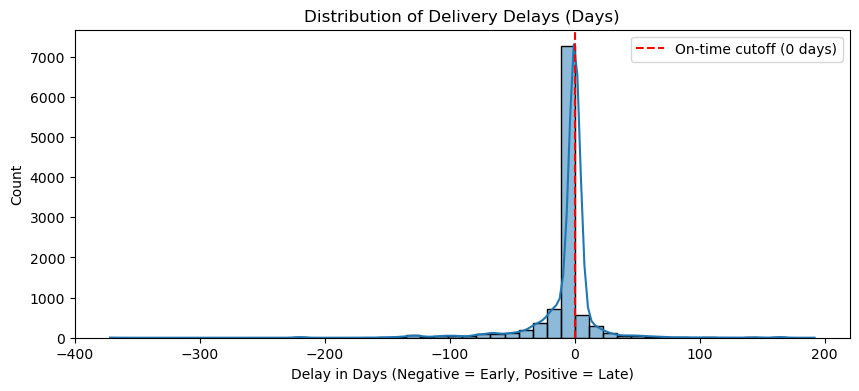

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
sns.histplot(df['delay'].dropna(), bins=50, kde=True)
plt.axvline(0, color='red', linestyle='--', label='On-time cutoff (0 days)')
plt.title('Distribution of Delivery Delays (Days)')
plt.xlabel('Delay in Days (Negative = Early, Positive = Late)')
plt.ylabel('Count')
plt.legend()
plt.show()

**Reading the delay distribution:** the bulk of PO lines sit at exactly 0 days (median = 0), with a long tail of early deliveries (down to about -370 days) and a shorter tail of late deliveries (up to about +190 days). The red dashed line marks the on-time cutoff: everything to its right is late.

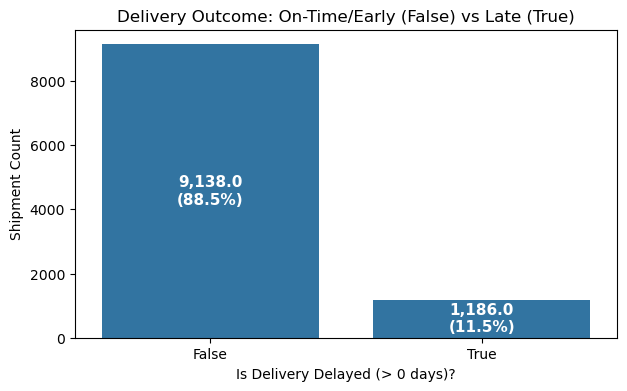

Overall Delivery Risk Distribution:
is_delayed
False    88.51%
True     11.49%
Name: proportion, dtype: str


In [33]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(x=df['is_delayed'])
plt.title('Delivery Outcome: On-Time/Early (False) vs Late (True)')
plt.xlabel('Is Delivery Delayed (> 0 days)?')
plt.ylabel('Shipment Count')

total = len(df['is_delayed'].dropna())
for p in ax.patches:
    height = p.get_height()
    pct = (height / total) * 100
    ax.annotate(f'{height:,}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)
plt.show()

print('Overall Delivery Risk Distribution:')
print(df['is_delayed'].value_counts(normalize=True).apply(lambda x: f'{x:.2%}'))


From the above visual can see that late delivery are a minority class

## 1. Exploratory Data Analysis (EDA): What Drives Delivery Delays?

In global procurement operations, late delivery risk varies significantly by fulfillment method, logistics mode, and commercial contract terms. Let us investigate each operational dimension.

,Fulfill Via,Total Shipments,Late Rate (%)
0,Direct Drop,4920,5.26
1,From RDC,5404,17.15


/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipykernel_84155/2689197035.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fulfill_summary, x='Fulfill Via', y='Late Rate (%)', palette='Blues_r')


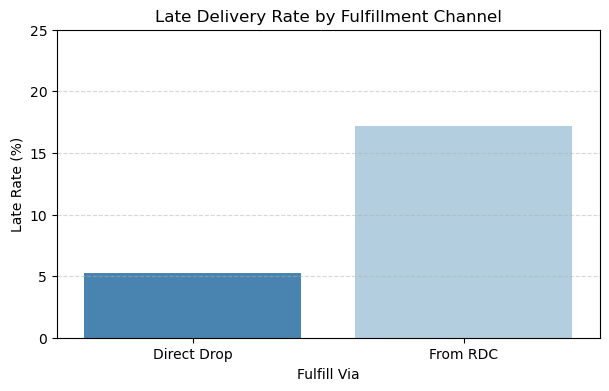

In [34]:
# 1. Fulfillment Channel Risk: Direct Drop vs. From RDC
fulfill_summary = df.groupby('Fulfill Via')['is_delayed'].agg(['count', 'mean']).reset_index()
fulfill_summary.columns = ['Fulfill Via', 'Total Shipments', 'Late Rate (%)']
fulfill_summary['Late Rate (%)'] = (fulfill_summary['Late Rate (%)'] * 100).round(2)
display(fulfill_summary)

plt.figure(figsize=(7, 4))
sns.barplot(data=fulfill_summary, x='Fulfill Via', y='Late Rate (%)', palette='Blues_r')
plt.title('Late Delivery Rate by Fulfillment Channel')
plt.ylabel('Late Rate (%)')
plt.ylim(0, 25)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

**Fulfilment channel:** `From RDC` lines (regional distribution centre replenishments) are late **17.15%** of the time versus **5.26%** for `Direct Drop`, about 3x higher. This is the strongest operational signal found in the EDA.

In [52]:
# 2. Logistics & Shipment Mode Risk
shipment_summary = df.groupby('Shipment Mode')['is_delayed'].agg(['count', 'mean']).reset_index()
shipment_summary.columns = ['Shipment Mode', 'Total Shipments', 'Late Rate (%)']
shipment_summary['Late Rate (%)'] = (shipment_summary['Late Rate (%)'] * 100).round(2)
shipment_summary = shipment_summary.sort_values(by='Late Rate (%)', ascending=False)
display(shipment_summary)

,Shipment Mode,Total Shipments,Late Rate (%)
3,Ocean,371,17.52
4,Truck,2830,16.08
1,Air Charter,650,11.54
0,Air,6113,9.60
2,Not Applicable,360,1.11


/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipykernel_84155/1255056395.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=shipment_summary, x='Shipment Mode', y='Late Rate (%)', palette='Reds_r')


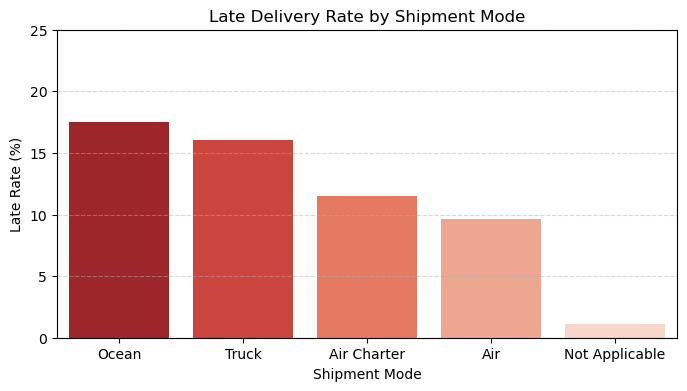

In [54]:
plt.figure(figsize=(8, 4))
sns.barplot(data=shipment_summary, x='Shipment Mode', y='Late Rate (%)', palette='Reds_r')
plt.title('Late Delivery Rate by Shipment Mode')
plt.ylabel('Late Rate (%)')
plt.ylim(0, 25)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

We can clearly see that the late delivery rate is fairly homogeneous across the different shipment modes

**Nuance on shipment modes:** the differences are real, not entirely flat. `Ocean` (17.5%) and `Truck` (16.1%) are late roughly 6 to 8 points more often than `Air` (9.6%). The `Not Applicable` group (about 1%) is tiny and behaves very differently. Shipment mode matters, but less than the fulfilment channel above (17.2% vs 5.3%), which is why it ranks lower in the feature importance later.

In [55]:
# 3. Commercial INCO Terms Risk
inco_summary = df.groupby('Vendor INCO Term')['is_delayed'].agg(['count', 'mean']).reset_index()
inco_summary.columns = ['Vendor INCO Term', 'Total Shipments', 'Late Rate (%)']
inco_summary['Late Rate (%)'] = (inco_summary['Late Rate (%)'] * 100).round(2)
inco_summary = inco_summary.sort_values(by='Total Shipments', ascending=False).head(8)
display(inco_summary)

,Vendor INCO Term,Total Shipments,Late Rate (%)
7,N/A - From RDC,5404,17.15
5,EXW,2778,4.97
3,DDP,1443,8.04
6,FCA,397,1.01
1,CIP,275,0.36
4,DDU,15,0.00
2,DAP,9,0.00
0,CIF,3,0.00


/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipykernel_84155/3199818008.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=inco_summary, x='Vendor INCO Term', y='Late Rate (%)', palette='Greens_r')


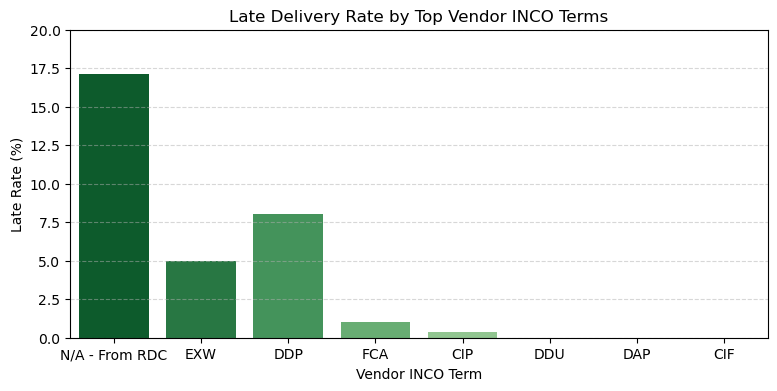

In [56]:
plt.figure(figsize=(9, 4))
sns.barplot(data=inco_summary, x='Vendor INCO Term', y='Late Rate (%)', palette='Greens_r')
plt.title('Late Delivery Rate by Top Vendor INCO Terms')
plt.ylabel('Late Rate (%)')
plt.ylim(0, 20)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

**INCO terms:** `N/A - From RDC` has exactly the same count and late rate as `From RDC` (5,404 lines, 17.15%), so it is the same information as `Fulfill Via` (redundant). Among direct shipments, `DDP` (8.0%) is riskier than `EXW` (5.0%), `FCA` (1.0%) and `CIP` (0.4%). `DDU`, `DAP` and `CIF` have fewer than 20 lines, so their 0% late rates are not reliable.

In [37]:
# 4. Product Group Delay Risk
product_summary = df.groupby('Product Group')['is_delayed'].agg(['count', 'mean']).reset_index()
product_summary.columns = ['Product Group', 'Total Shipments', 'Late Rate (%)']
product_summary['Late Rate (%)'] = (product_summary['Late Rate (%)'] * 100).round(2)
display(product_summary)

,Product Group,Total Shipments,Late Rate (%)
0,ACT,16,0.00
1,ANTM,22,0.00
2,ARV,8550,12.55
3,HRDT,1728,6.54
4,MRDT,8,0.00


/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipykernel_84155/4155589525.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=product_summary, x='Product Group', y='Late Rate (%)', palette='Greens_r')


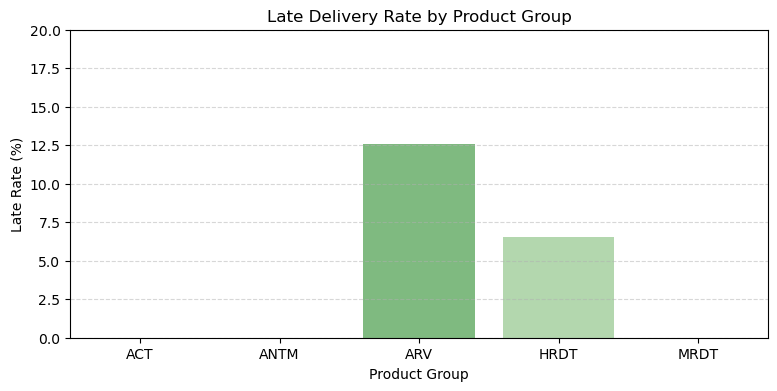

In [57]:
plt.figure(figsize=(9, 4))
sns.barplot(data=product_summary, x='Product Group', y='Late Rate (%)', palette='Greens_r')
plt.title('Late Delivery Rate by Product Group')
plt.ylabel('Late Rate (%)')
plt.ylim(0, 20)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

**Product groups:** `ARV` lines are late 12.55% of the time versus 6.54% for `HRDT`. The three small groups (`ACT`, `ANTM`, `MRDT`) show 0% late, but with only 8 to 22 lines each this is not statistically meaningful.

### Mutual Information Analysis with Target Variable
Mutual Information (MI) measures the mutual dependence between categorical features and the binary late delivery target (`is_delayed`), quantifying how much information each procurement feature provides.

/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipykernel_84155/2098217791.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=mi_df, x='Mutual Information', y='Feature', palette='viridis')


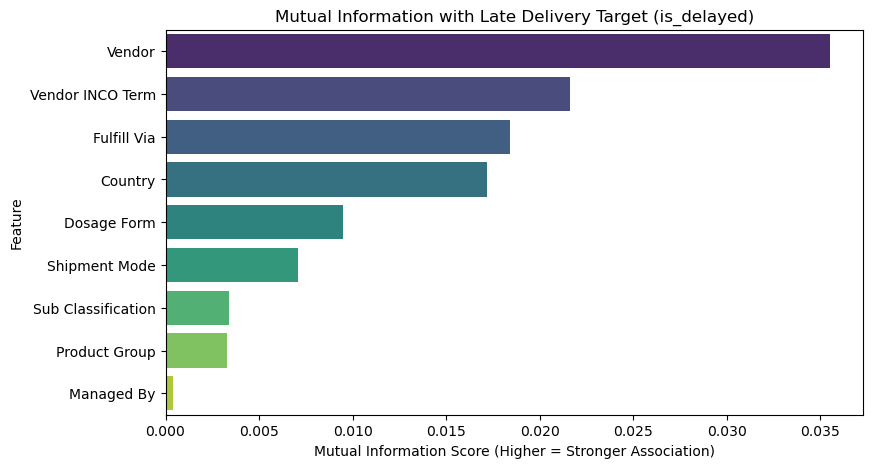

,Feature,Mutual Information
0,Vendor,0.0355
1,Vendor INCO Term,0.0216
2,Fulfill Via,0.0184
3,Country,0.0172
4,Dosage Form,0.0095
5,Shipment Mode,0.0071
6,Sub Classification,0.0034
7,Product Group,0.0033
8,Managed By,0.0004


In [38]:
from sklearn.metrics import mutual_info_score

categorical_cols_for_mi = [
    'Country', 'Managed By', 'Fulfill Via', 'Vendor INCO Term', 
    'Shipment Mode', 'Product Group', 'Sub Classification', 'Vendor', 'Dosage Form'
]

def calculate_mi(series):
    clean_series = series.fillna('Missing')
    return mutual_info_score(clean_series, df['is_delayed'].astype(int))

mi_scores = df[categorical_cols_for_mi].apply(calculate_mi).sort_values(ascending=False)
mi_df = pd.DataFrame({'Feature': mi_scores.index, 'Mutual Information': mi_scores.values.round(4)})

plt.figure(figsize=(9, 5))
sns.barplot(data=mi_df, x='Mutual Information', y='Feature', palette='viridis')
plt.title('Mutual Information with Late Delivery Target (is_delayed)')
plt.xlabel('Mutual Information Score (Higher = Stronger Association)')
plt.show()
display(mi_df)

**Reading the mutual information (MI) scores:** `Vendor` (0.036), `Vendor INCO Term` (0.022), `Fulfill Via` (0.018) and `Country` (0.017) carry the most information about late delivery; `Managed By` carries almost none.

Two caveats: (1) absolute values are small because the target is imbalanced (11.5% positives), so compare features relative to each other; (2) MI favours columns with many categories such as `Vendor`, so part of its lead is a cardinality effect. This is one reason we later group rare categories into `OTHER`.

## 2. ERP Anomaly Parsing & Point-in-Time Feature Engineering

In real enterprise ERP data (SAP, Oracle, SCMS), numeric fields often contain unstructured reference text (e.g. `"Weight Captured Separately"`, `"Freight Included in Commodity Cost"`, or `"See ASN-..."`).
Rather than discarding rows, we parse numeric values and extract high-signal categorical flags.

Furthermore, we enforce a strict **Point-in-Time Contract** to prevent data leakage:
- Exclude post-delivery variables (`Delivered to Client Date`, `Delivery Recorded Date`, `delay`).
- Retain only attributes known when the PO is scheduled.

In [39]:
# 1. Parse numeric values from ERP text columns
df['weight_numeric'] = pd.to_numeric(df['Weight (Kilograms)'], errors='coerce')
df['freight_numeric'] = pd.to_numeric(df['Freight Cost (USD)'], errors='coerce')

# 2. Extract domain categorical status flags
def extract_weight_status(val):
    if pd.isna(val):
        return 'missing'
    s = str(val).strip()
    if 'Weight Captured Separately' in s:
        return 'captured_separately'
    elif 'See ' in s:
        return 'consolidated'
    elif s.replace('.', '', 1).isdigit():
        return 'numeric'
    return 'other'

def extract_freight_status(val):
    if pd.isna(val):
        return 'missing'
    s = str(val).strip()
    if 'Freight Included' in s:
        return 'included_in_commodity'
    elif 'Invoiced Separately' in s:
        return 'invoiced_separately'
    elif 'See ' in s:
        return 'consolidated'
    elif s.replace('.', '', 1).isdigit():
        return 'numeric'
    return 'other'

df['weight_status'] = df['Weight (Kilograms)'].apply(extract_weight_status)
df['freight_status'] = df['Freight Cost (USD)'].apply(extract_freight_status)

print("Weight Status Distribution:")
print(df['weight_status'].value_counts())
print("\nFreight Status Distribution:")
print(df['freight_status'].value_counts())

Weight Status Distribution:
weight_status
numeric                6372
consolidated           2445
captured_separately    1507
Name: count, dtype: int64

Freight Status Distribution:
freight_status
numeric                  6198
consolidated             2445
included_in_commodity    1442
invoiced_separately       239
Name: count, dtype: int64


**What the parsing found:** only 6,372 of 10,324 weights and 6,198 freight costs are real numbers. The rest are ERP reference texts: 2,445 lines point to another shipment (`See ASN-... / See DN-...`), 1,507 have `Weight Captured Separately`, 1,442 have `Freight Included in Commodity Cost` and 239 have `Invoiced Separately`. Dropping these rows would lose about 40% of the data, so we keep the numeric value (when available) **and** a status flag. The flag itself can be predictive, as the feature importance later confirms.

In [40]:
# 3. Known-at-Booking Feature Engineering
df['is_late'] = df['is_delayed'].astype(int)

# Planned Lead Time in days (Scheduled Delivery Date - PO Sent to Vendor Date)
df['planned_lead_time_days'] = (df['Scheduled Delivery Date'] - df['PO Sent to Vendor Date']).dt.days
df['po_date_missing'] = df['planned_lead_time_days'].isnull().astype(int)

# Seasonality features from Scheduled Delivery Date
df['scheduled_year'] = df['Scheduled Delivery Date'].dt.year
df['scheduled_month'] = df['Scheduled Delivery Date'].dt.month
df['scheduled_quarter'] = df['Scheduled Delivery Date'].dt.quarter
df['scheduled_dayofweek'] = df['Scheduled Delivery Date'].dt.dayofweek

# Log-transform highly skewed commercial financials
df['log_line_item_value'] = np.log1p(df['Line Item Value'].clip(lower=0))
df['log_line_item_quantity'] = np.log1p(df['Line Item Quantity'].clip(lower=0))

# Clean categorical representations
df['dosage_clean'] = df['Dosage'].fillna('Not Applicable')
df['shipment_mode_clean'] = df['Shipment Mode'].fillna('Not Applicable')
df['insurance_clean'] = df['Line Item Insurance (USD)'].fillna(0)

print("Engineered feature set ready. Total rows:", len(df))

Engineered feature set ready. Total rows: 10324


**Known-at-booking features** (everything here is available when the PO is scheduled):
- `planned_lead_time_days` = scheduled delivery date minus PO sent date, plus `po_date_missing` flag. It is missing for `From RDC` lines because no PO date is recorded for them.
- Seasonality from the scheduled date: year, month, quarter, day of week.
- `log1p` of line value and quantity, to tame their heavy right skew.
- Cleaned versions of the categorical columns and the integer target `is_late`.

No post-delivery information is used.

## 3. Dataset Splitting & Split-First Preprocessing Hygiene

To prevent data leakage:
1. Split data into **60% Train / 20% Validation / 20% Test** using stratified sampling on `is_late`.
2. Imputation statistics (medians) are computed **strictly on `df_train`** and applied downstream.
3. Sparse categorical categories (< 20 occurrences in train) are grouped into `'OTHER'` based solely on training frequency.

In [41]:
from sklearn.model_selection import train_test_split

# Split into 60% Train / 20% Val / 20% Test
df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=42, stratify=df['is_late'])
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=42, stratify=df_train_full['is_late'])

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print(f"Train set:       {len(df_train):,} rows ({len(df_train)/len(df):.1%}) - Late rate: {df_train['is_late'].mean():.2%}")
print(f"Validation set:  {len(df_val):,} rows ({len(df_val)/len(df):.1%}) - Late rate: {df_val['is_late'].mean():.2%}")
print(f"Test set:        {len(df_test):,} rows ({len(df_test)/len(df):.1%}) - Late rate: {df_test['is_late'].mean():.2%}")

y_train = df_train['is_late'].values
y_val = df_val['is_late'].values
y_test = df_test['is_late'].values

Train set:       6,194 rows (60.0%) - Late rate: 11.49%
Validation set:  2,065 rows (20.0%) - Late rate: 11.48%
Test set:        2,065 rows (20.0%) - Late rate: 11.48%


**Split check:** 60% train / 20% validation / 20% test, stratified on `is_late`, so each split keeps the same late rate (about 11.5%). Validation is used to choose models, hyperparameters and the threshold; the test set is only touched once at the end.

In [42]:
# Compute medians strictly on df_train
train_lead_median = df_train['planned_lead_time_days'].median()
train_weight_median = df_train['weight_numeric'].median()
train_freight_median = df_train['freight_numeric'].median()

print(f"Train Imputation Medians:")
print(f"  Planned Lead Time: {train_lead_median:.1f} days")
print(f"  Weight:            {train_weight_median:.1f} kg")
print(f"  Freight Cost:      ${train_freight_median:.2f}")

for d in [df_train, df_val, df_test]:
    d['planned_lead_time_clean'] = d['planned_lead_time_days'].fillna(train_lead_median)
    d['weight_clean'] = d['weight_numeric'].fillna(train_weight_median)
    d['freight_clean'] = d['freight_numeric'].fillna(train_freight_median)

# Curate long-tail sparse categories (< 20 occurrences in df_train)
high_card_cols = ['Country', 'Vendor', 'Manufacturing Site']
frequent_categories = {}

for col in high_card_cols:
    counts = df_train[col].value_counts()
    frequent_categories[col] = set(counts[counts >= 20].index)
    print(f"Retained {len(frequent_categories[col])} frequent categories for '{col}' (>= 20 training samples).")
    for d in [df_train, df_val, df_test]:
        d[f'{col}_clean'] = d[col].apply(lambda x: x if x in frequent_categories[col] else 'OTHER')

Train Imputation Medians:
  Planned Lead Time: 92.5 days
  Weight:            1080.0 kg
  Freight Cost:      $6008.28
Retained 23 frequent categories for 'Country' (>= 20 training samples).
Retained 21 frequent categories for 'Vendor' (>= 20 training samples).
Retained 30 frequent categories for 'Manufacturing Site' (>= 20 training samples).


Medians are computed **only on the training set** and reused for validation and test, which prevents leakage. Rare categories (fewer than 20 training lines) are grouped into `OTHER`; this keeps 23 countries, 21 vendors and 30 manufacturing sites.

In [43]:
from sklearn.feature_extraction import DictVectorizer

cat_features = [
    'Country_clean', 'Managed By', 'Fulfill Via', 'Vendor INCO Term', 
    'shipment_mode_clean', 'Product Group', 'Sub Classification', 
    'Vendor_clean', 'Manufacturing Site_clean', 'First Line Designation',
    'dosage_clean', 'weight_status', 'freight_status'
]

num_features = [
    'planned_lead_time_clean', 'po_date_missing', 'scheduled_year', 'scheduled_month',
    'scheduled_quarter', 'scheduled_dayofweek', 'log_line_item_value', 
    'log_line_item_quantity', 'Pack Price', 'Unit Price', 'insurance_clean',
    'weight_clean', 'freight_clean'
]

all_features = cat_features + num_features
print(f"Total modeling features: {len(all_features)} ({len(cat_features)} categorical, {len(num_features)} numerical)")

dv = DictVectorizer(sparse=False)

train_dicts = df_train[all_features].to_dict(orient='records')
val_dicts = df_val[all_features].to_dict(orient='records')
test_dicts = df_test[all_features].to_dict(orient='records')

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)

print(f"Transformed matrix dimensions: X_train = {X_train.shape}, X_val = {X_val.shape}, X_test = {X_test.shape}")

Total modeling features: 26 (13 categorical, 13 numerical)
Transformed matrix dimensions: X_train = (6194, 183), X_val = (2065, 183), X_test = (2065, 183)


`DictVectorizer` one-hot encodes the 13 categorical features and passes the 13 numeric features through, giving **183 columns**. It is fitted on the training set only, then applied to validation and test.

## 4. Multi-Model Training & Hyperparameter Tuning

We train and evaluate three distinct model architectures:
1. **Logistic Regression (Linear Baseline):** Regularized linear classification with balanced class weights.
2. **Random Forest Classifier (Bagging Ensemble):** Decision tree ensemble with tuning of depth, sample leaf, and tree count.
3. **XGBoost Classifier (Gradient Boosting):** Gradient-boosted decision trees with learning rate and depth tuning.

In [44]:
# Model 1: Logistic Regression with Regularization Tuning
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

c_values = [0.001, 0.01, 0.1, 1.0, 10.0]
lr_records = []

for c in c_values:
    lr = LogisticRegression(C=c, class_weight='balanced', max_iter=1000, random_state=42)
    lr.fit(X_train_scaled, y_train)
    y_pred = lr.predict_proba(X_val_scaled)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    pr_auc = average_precision_score(y_val, y_pred)
    lr_records.append({'C': c, 'ROC_AUC': round(auc, 4), 'PR_AUC': round(pr_auc, 4)})

lr_tuning_df = pd.DataFrame(lr_records)
display(lr_tuning_df)
best_c = lr_tuning_df.sort_values(by='ROC_AUC', ascending=False).iloc[0]['C']
print(f"Optimal Logistic Regression C: {best_c}")

,C,ROC_AUC,PR_AUC
0,0.001,0.8096,0.3050
1,0.010,0.8126,0.3164
2,0.100,0.8130,0.3192
3,1.000,0.8110,0.3198
4,10.000,0.8104,0.3145


Optimal Logistic Regression C: 0.1


**Model 1 - Logistic Regression (baseline):** after standard scaling and with balanced class weights, ROC-AUC barely moves with the regularisation strength `C` (0.810 to 0.813), and `C = 0.1` is best. A linear model reaches about 0.81, which is a solid baseline but leaves room for non-linear models.

In [45]:
# Model 2: Random Forest Classifier with Hyperparameter Tuning
from sklearn.ensemble import RandomForestClassifier

rf_records = []
for depth in [5, 10, 15]:
    for leaf in [1, 3, 5]:
        for trees in [50, 100]:
            rf = RandomForestClassifier(n_estimators=trees, max_depth=depth, min_samples_leaf=leaf, random_state=42, n_jobs=-1)
            rf.fit(X_train, y_train)
            y_pred = rf.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)
            rf_records.append({'max_depth': depth, 'min_samples_leaf': leaf, 'n_estimators': trees, 'ROC_AUC': round(auc, 4)})

rf_tuning_df = pd.DataFrame(rf_records).sort_values(by='ROC_AUC', ascending=False)
print("Top 5 Random Forest configurations:")
display(rf_tuning_df.head(5))
best_rf_params = rf_tuning_df.iloc[0]

Top 5 Random Forest configurations:


,max_depth,min_samples_leaf,n_estimators,ROC_AUC
13,15,1,100,0.8724
15,15,3,100,0.8695
14,15,3,50,0.8664
7,10,1,100,0.8659
12,15,1,50,0.8655


**Model 2 - Random Forest:** the best setting is `max_depth=15, min_samples_leaf=1, n_estimators=100` with ROC-AUC **0.872**. Deeper trees were consistently better, and the best value sits at the edge of the grid we searched, so trying `max_depth > 15` might help further.

In [46]:
# Model 3: XGBoost Classifier with Hyperparameter Tuning
from xgboost import XGBClassifier

xgb_records = []
for lr_rate in [0.01, 0.05, 0.1]:
    for depth in [3, 5, 8]:
        xgb = XGBClassifier(n_estimators=120, learning_rate=lr_rate, max_depth=depth, min_child_weight=3, random_state=42, eval_metric='logloss')
        xgb.fit(X_train, y_train)
        y_pred = xgb.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        pr_auc = average_precision_score(y_val, y_pred)
        xgb_records.append({'learning_rate': lr_rate, 'max_depth': depth, 'ROC_AUC': round(auc, 4), 'PR_AUC': round(pr_auc, 4)})

xgb_tuning_df = pd.DataFrame(xgb_records).sort_values(by='ROC_AUC', ascending=False)
print("Top 5 XGBoost configurations:")
display(xgb_tuning_df.head(5))
best_xgb_params = xgb_tuning_df.iloc[0]

Top 5 XGBoost configurations:


,learning_rate,max_depth,ROC_AUC,PR_AUC
5,0.05,8,0.8986,0.4818
8,0.10,8,0.8982,0.4672
7,0.10,5,0.8896,0.4543
2,0.01,8,0.8884,0.4670
4,0.05,5,0.8856,0.4544


**Model 3 - XGBoost:** the best setting is `learning_rate=0.05, max_depth=8` with ROC-AUC **0.899** and PR-AUC 0.482. As for Random Forest, the best depth is at the edge of the grid we tested.

In [47]:
# Model Comparison & Champion Selection
best_lr = LogisticRegression(C=best_c, class_weight='balanced', max_iter=1000, random_state=42)
best_lr.fit(X_train_scaled, y_train)
lr_val_preds = best_lr.predict_proba(X_val_scaled)[:, 1]

best_rf = RandomForestClassifier(
    n_estimators=int(best_rf_params['n_estimators']),
    max_depth=int(best_rf_params['max_depth']),
    min_samples_leaf=int(best_rf_params['min_samples_leaf']),
    random_state=42, n_jobs=-1
)
best_rf.fit(X_train, y_train)
rf_val_preds = best_rf.predict_proba(X_val)[:, 1]

best_xgb = XGBClassifier(
    n_estimators=120,
    learning_rate=float(best_xgb_params['learning_rate']),
    max_depth=int(best_xgb_params['max_depth']),
    min_child_weight=3,
    random_state=42, eval_metric='logloss'
)
best_xgb.fit(X_train, y_train)
xgb_val_preds = best_xgb.predict_proba(X_val)[:, 1]

comparison_df = pd.DataFrame([
    {'Model Architecture': 'Logistic Regression (Baseline)', 'Val ROC-AUC': roc_auc_score(y_val, lr_val_preds), 'Val PR-AUC': average_precision_score(y_val, lr_val_preds)},
    {'Model Architecture': 'Random Forest Classifier', 'Val ROC-AUC': roc_auc_score(y_val, rf_val_preds), 'Val PR-AUC': average_precision_score(y_val, rf_val_preds)},
    {'Model Architecture': 'XGBoost Classifier (Champion)', 'Val ROC-AUC': roc_auc_score(y_val, xgb_val_preds), 'Val PR-AUC': average_precision_score(y_val, xgb_val_preds)}
])
display(comparison_df.round(4))

,Model Architecture,Val ROC-AUC,Val PR-AUC
0,Logistic Regression (Baseline),0.8130,0.3192
1,Random Forest Classifier,0.8724,0.4165
2,XGBoost Classifier (Champion),0.8986,0.4818


**Model comparison (validation set):**

| Model | ROC-AUC | PR-AUC |
| :--- | :---: | :---: |
| Logistic Regression | 0.813 | 0.319 |
| Random Forest | 0.872 | 0.417 |
| **XGBoost** | **0.899** | **0.482** |

The ranking is clear: XGBoost > Random Forest > Logistic Regression. The gap suggests non-linear interactions (for example fulfilment channel x country x shipment mode) that a linear model cannot capture. For reference, a random classifier would have a PR-AUC of about 0.115 (the late rate), so XGBoost is roughly 4x better than chance. XGBoost is selected as the champion model.

## 5. Decision Threshold Optimization for Supply Chain SLA Risk

In real procurement systems with ~11.5% late delivery prevalence, a standard `0.50` decision threshold is suboptimal: it biases toward the majority class and fails to catch high-cost supplier delays.
We tune the decision threshold on the Validation set to maximize the **F1-Score** and maintain high recall.

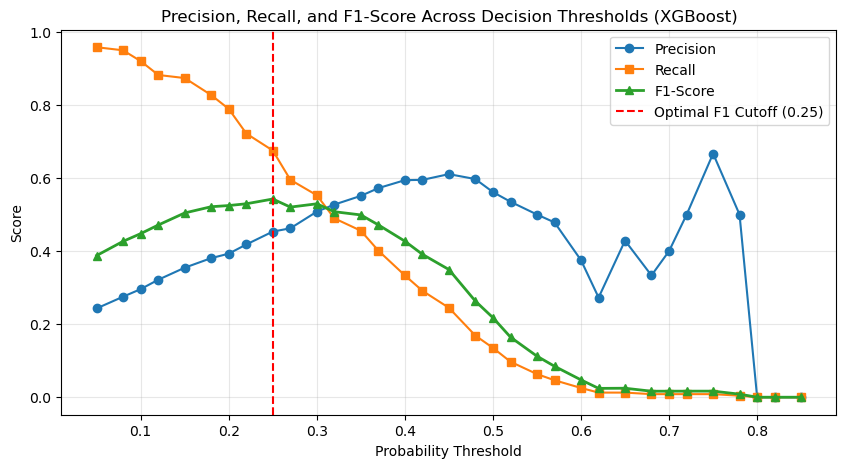

Optimal Decision Threshold: 0.25 (Max F1: 0.5424)


In [48]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.linspace(0.05, 0.85, 33)
threshold_metrics = []

for t in thresholds:
    preds = (xgb_val_preds >= t).astype(int)
    prec = precision_score(y_val, preds, zero_division=0)
    rec = recall_score(y_val, preds, zero_division=0)
    f1 = f1_score(y_val, preds, zero_division=0)
    threshold_metrics.append({'threshold': round(t, 2), 'precision': prec, 'recall': rec, 'f1': f1})

thresh_df = pd.DataFrame(threshold_metrics)

plt.figure(figsize=(10, 5))
plt.plot(thresh_df['threshold'], thresh_df['precision'], label='Precision', marker='o')
plt.plot(thresh_df['threshold'], thresh_df['recall'], label='Recall', marker='s')
plt.plot(thresh_df['threshold'], thresh_df['f1'], label='F1-Score', marker='^', linewidth=2)
optimal_idx = thresh_df['f1'].idxmax()
optimal_threshold = thresh_df.loc[optimal_idx, 'threshold']

plt.axvline(optimal_threshold, color='red', linestyle='--', label=f'Optimal F1 Cutoff ({optimal_threshold:.2f})')
plt.title('Precision, Recall, and F1-Score Across Decision Thresholds (XGBoost)')
plt.xlabel('Probability Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"Optimal Decision Threshold: {optimal_threshold:.2f} (Max F1: {thresh_df.loc[optimal_idx, 'f1']:.4f})")

**Chosen threshold: 0.25** (validation F1 = 0.542). The curve shows the usual trade-off: a low threshold catches more late lines (high recall) but raises false alarms (low precision), and a high threshold does the opposite. Because a missed late delivery is usually costlier than an unnecessary follow-up, a threshold below the default 0.50 is appropriate. The threshold was tuned on the validation set only.

## 6. Final Evaluation on Unseen Test Set

We test the champion XGBoost model on the held-out 20% test dataset using our tuned optimal decision threshold.

=== FINAL TEST EVALUATION (XGBoost) ===
Test ROC-AUC: 0.8887
Test PR-AUC:  0.4627

Classification Report (at threshold 0.25):
                 precision    recall  f1-score   support

On-Time / Early       0.94      0.89      0.92      1828
           Late       0.41      0.59      0.48       237

       accuracy                           0.86      2065
      macro avg       0.68      0.74      0.70      2065
   weighted avg       0.88      0.86      0.87      2065



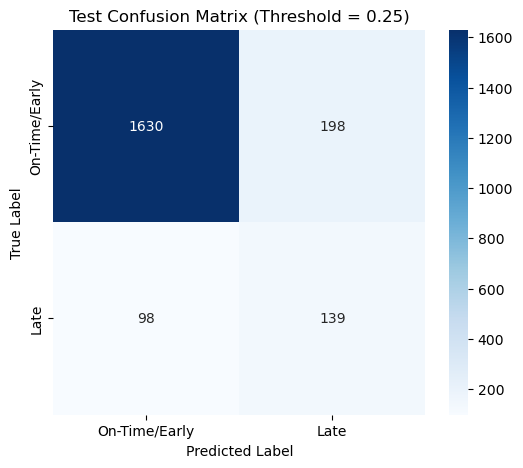

In [49]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

xgb_test_preds = best_xgb.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, xgb_test_preds)
test_pr_auc = average_precision_score(y_test, xgb_test_preds)
test_binary_preds = (xgb_test_preds >= optimal_threshold).astype(int)

print(f"=== FINAL TEST EVALUATION (XGBoost) ===")
print(f"Test ROC-AUC: {test_auc:.4f}")
print(f"Test PR-AUC:  {test_pr_auc:.4f}\n")
print(f"Classification Report (at threshold {optimal_threshold:.2f}):")
print(classification_report(y_test, test_binary_preds, target_names=['On-Time / Early', 'Late']))

cm = confusion_matrix(y_test, test_binary_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['On-Time/Early', 'Late'], yticklabels=['On-Time/Early', 'Late'])
plt.title(f'Test Confusion Matrix (Threshold = {optimal_threshold:.2f})')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

**Test-set results (never seen during tuning):** ROC-AUC **0.889**, PR-AUC **0.463**. These are very close to the validation numbers (0.899 / 0.482), so we are not overfitting to the validation set.

At threshold 0.25 the model catches **59% of late deliveries** (recall) and **41% of its "late" alerts are correct** (precision), while correctly clearing 89% of on-time/early lines. In practice a buyer would review a manageable subset of POs and catch most of the problematic ones, far better than checking POs at random (11.5% hit rate).

## 7. Feature Importance & Domain Interpretation

Understanding what drives late delivery risk empowers procurement officers to negotiate safer lead times, adjust logistics routing, or require enhanced ASN confirmations.

/var/folders/v0/qcvy_c7905j68vvc9hgg3qw40000gn/T/ipykernel_84155/3407963087.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df.head(20), x='importance', y='feature', palette='mako')


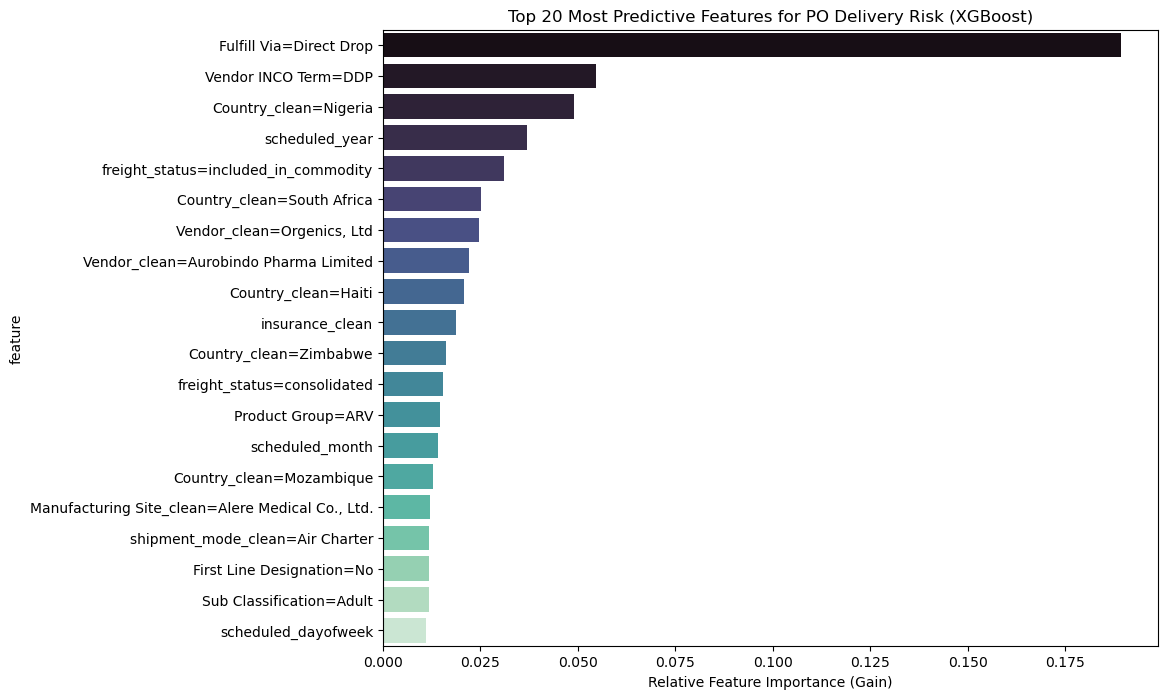

,feature,importance
26,Fulfill Via=Direct Drop,0.189265
78,Vendor INCO Term=DDP,0.054702
13,Country_clean=Nigeria,0.049065
173,scheduled_year,0.036911
162,freight_status=included_in_commodity,0.031173
16,Country_clean=South Africa,0.025133
97,"Vendor_clean=Orgenics, Ltd",0.024560
85,Vendor_clean=Aurobindo Pharma Limited,0.022131
9,Country_clean=Haiti,0.020791
165,insurance_clean,0.018866


In [50]:
importances = best_xgb.feature_importances_
feature_names = dv.get_feature_names_out()

fi_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=fi_df.head(20), x='importance', y='feature', palette='mako')
plt.title('Top 20 Most Predictive Features for PO Delivery Risk (XGBoost)')
plt.xlabel('Relative Feature Importance (Gain)')
plt.show()

display(fi_df.head(20))

**Feature importance (XGBoost):**
- `Fulfill Via = Direct Drop` is by far the strongest feature (0.19), which matches the EDA (5% vs 17% late).
- Commercial and logistics terms follow (`Vendor INCO Term = DDP`, `freight_status = included_in_commodity`), confirming that the ERP text flags carry signal.
- Several destination countries (Nigeria, South Africa, Haiti, Zimbabwe...) and vendors appear, showing route and supplier effects.
- `scheduled_year` also ranks high, which suggests performance changed over time; periodic retraining is advisable.

Importance shows what the model *uses*, not what *causes* delays.

## 8. Model Serialization for Production Deployment

We package the trained `DictVectorizer`, champion `XGBClassifier`, optimal decision threshold, training medians, and frequent category sets into `model.bin` for consumption by the FastAPI production service (`serve.py`).

In [51]:
import pickle
import os

model_dir = "."  # run the notebook from the project folder
os.makedirs(model_dir, exist_ok=True)
model_path = os.path.join(model_dir, "model.bin")

artifact = {
    'dv': dv,
    'model': best_xgb,
    'optimal_threshold': float(optimal_threshold),
    'train_medians': {
        'planned_lead_time': float(train_lead_median),
        'weight': float(train_weight_median),
        'freight': float(train_freight_median)
    },
    'frequent_categories': {k: list(v) for k, v in frequent_categories.items()},
    'features': all_features
}

with open(model_path, 'wb') as f_out:
    pickle.dump(artifact, f_out)

print(f"Model successfully saved to: {model_path}")
print(f"Artifact file size: {os.path.getsize(model_path) / 1024:.2f} KB")

# Verification test loading from disk
with open(model_path, 'rb') as f_in:
    loaded = pickle.load(f_in)

test_record = df_test.iloc[0][all_features].to_dict()
X_test_sample = loaded['dv'].transform([test_record])
sample_prob = loaded['model'].predict_proba(X_test_sample)[0, 1]
sample_pred = bool(sample_prob >= loaded['optimal_threshold'])

print("\n--- End-to-End Inference Verification ---")
print(f"Country:                  {test_record['Country_clean']}")
print(f"Fulfill Via:              {test_record['Fulfill Via']}")
print(f"Predicted Late Risk Prob: {sample_prob:.4f}")
print(f"Optimal Threshold:        {loaded['optimal_threshold']:.2f}")
print(f"Predicted Late Breach:    {sample_pred}")
print("Pipeline verified successfully and ready for deployment!")

Model successfully saved to: /Users/sandrab/procurement_gen_ai/datatalksclub/ml-zoomcamp2026/7-projects/midterm-supplier-risk/model.bin
Artifact file size: 375.22 KB

--- End-to-End Inference Verification ---
Country:                  Uganda
Fulfill Via:              From RDC
Predicted Late Risk Prob: 0.1035
Optimal Threshold:        0.25
Predicted Late Breach:    False
Pipeline verified successfully and ready for deployment!


**Result:** the full pipeline (vectorizer, XGBoost model, threshold, training medians, rare-category lists) is saved to `model.bin` and reloads correctly for a sample prediction.

**Next steps**
- `train.py` re-runs this pipeline as a script and regenerates `model.bin`.
- `serve.py` exposes the model through a FastAPI `POST /predict` endpoint.
- The `Dockerfile` packages the service for local and cloud deployment.